# 532 nm Spatial Characterization

**Source:** Coherent COMPASS 315M-100, CW 532 nm.  
**Detector geometry:** direct beam interception by the Basler acA3088-57uc; no camera lens or relay.  
**Native files:** 3088 × 2064 BayerRG12, three independently acquired frames per position, filenames indicating 8 µs exposure and reflective ND attenuation.

The two green photosites in each 2 × 2 Bayer cell are averaged without color demosaicing. This creates a green-superpixel grid with a 4.8 µm pitch. Beam widths are calculated from second moments inside an explicitly selected primary-lobe aperture. The experimenter identified the highest-intensity spot as the real beam; reflections outside that lobe are quantified rather than silently discarded.

For a second-moment diameter,

\[
D_{4\sigma,x}=4\sqrt{\langle(x-\bar{x})^2\rangle}, \qquad
D_{4\sigma,y}=4\sqrt{\langle(y-\bar{y})^2\rangle}.
\]

For caustic sensitivity analysis, the radius is \(w=D_{4\sigma}/2\) and

\[
w(z)=\sqrt{w_0^2+\left[\frac{M^2\lambda}{\pi w_0}(z-z_0)\right]^2}.
\]

In [1]:
from pathlib import Path
import json, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


def _locate_project_root(start=None):
    """Find the extracted project folder even if Jupyter was launched one directory above it."""
    start = Path.cwd() if start is None else Path(start)
    candidates = [start, *start.parents]
    for base in candidates:
        if (base / "laser_characterization.py").is_file() and (base / "outputs").is_dir():
            return base.resolve()
        try:
            children = sorted(base.glob("Laser_Characterization_Project*")) + sorted(base.glob("laser_characterization_project*"))
        except OSError:
            children = []
        for child in children:
            if child.is_dir() and (child / "laser_characterization.py").is_file() and (child / "outputs").is_dir():
                return child.resolve()
    raise FileNotFoundError(
        "Could not locate the laser-characterization project folder. Keep the notebooks, "
        "laser_characterization.py, laser_characterization_core.py, and outputs/ together."
    )

PROJECT_ROOT = _locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from laser_characterization import *

OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURE_DIR = PROJECT_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)
with (PROJECT_ROOT / "experiment_metadata.json").open() as handle:
    EXPERIMENT = json.load(handle)

# Raw data are optional for viewing the complete precomputed analysis.
# If present, they enable reconstruction of raw-data plots.
try:
    DATA_ROOT = find_data_root(PROJECT_ROOT)
except FileNotFoundError:
    DATA_ROOT = None
    for candidate in [
        PROJECT_ROOT / "data" / "532 and 1064",
        PROJECT_ROOT.parent / "532 and 1064",
        PROJECT_ROOT.parent / "data" / "532 and 1064",
    ]:
        if candidate.is_dir():
            DATA_ROOT = candidate.resolve()
            break
if DATA_ROOT is None:
    warnings.warn(
        "Raw data folder not found. This is OK: all precomputed result tables are included, "
        "and raw-data-only plots will be skipped."
    )


def source_path(stored_path):
    """Resolve a portable path stored relative to the `532 and 1064` data root."""
    p = Path(str(stored_path))
    if p.is_absolute() and p.exists():
        return p
    if DATA_ROOT is None:
        return p
    # Current V4 tables store paths relative to DATA_ROOT.
    q = Path(DATA_ROOT) / p
    if q.exists():
        return q
    # Backward compatibility for older absolute paths.
    parts = p.parts
    if "532 and 1064" in parts:
        i = parts.index("532 and 1064")
        q = Path(DATA_ROOT) / Path(*parts[i+1:])
        if q.exists():
            return q
    return q

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
print("Project:", PROJECT_ROOT)
print("Raw data:", DATA_ROOT if DATA_ROOT else "not mounted (using included precomputed results)")


Project: <project root>
Raw data: <project root>\data\532 and 1064


In [2]:
frames = pd.read_csv(OUTPUT_DIR / "spatial_frame_metrics.csv")
groups = pd.read_csv(OUTPUT_DIR / "spatial_group_metrics.csv")
fits = pd.read_csv(OUTPUT_DIR / "spatial_caustic_fit_sensitivity.csv")
no_lens_expansion = pd.read_csv(OUTPUT_DIR / "spatial_no_lens_expansion.csv")
pointing = pd.read_csv(OUTPUT_DIR / "spatial_pointing_summary.csv")
legacy = pd.read_csv(OUTPUT_DIR / "legacy_png_spatial_metrics.csv")

print(f"Native RAW frames: {len(frames)}")
print(f"Native z groups: {len(groups)}")
print(f"Supplemental PNG frames: {len(legacy)}")

Native RAW frames: 36
Native z groups: 12
Supplemental PNG frames: 20


## Native RAW measurement map

The focused scan has positions on both sides of the observed minimum, but five of the eight focused positions contain saturated Bayer cells inside the selected primary aperture. The three unsaturated focused positions are 5, 15, and 20 cm; that is not enough for an independent caustic fit.

In [3]:
qc_cols = [
    "focal", "position_cm", "n_frames", "n_primary_lobe_usable",
    "n_strict_unsaturated", "saturated_bayer_cells_primary_max",
    "primary_fraction_mean", "secondary_peak_ratio_mean",
    "gaussian_fit_nrmse_mean",
]
display(groups[qc_cols].round(4))

,focal,position_cm,n_frames,n_primary_lobe_usable,n_strict_unsaturated,saturated_bayer_cells_primary_max,primary_fraction_mean,secondary_peak_ratio_mean,gaussian_fit_nrmse_mean
0,no,0.0,3,3,3,0,0.6819,0.2374,0.0362
1,no,10.0,3,3,3,0,0.7121,0.2117,0.0398
2,no,20.0,3,3,3,0,0.9109,0.0530,0.0318
3,no,27.0,3,3,3,0,0.9299,0.0464,0.0254
4,yes,5.0,3,3,3,0,0.4095,0.4998,0.0341
5,yes,8.0,3,3,0,87,0.3456,0.5622,0.0383
6,yes,9.0,3,3,0,153,0.3897,0.5996,0.0290
7,yes,10.0,3,3,0,213,0.3911,0.6122,0.0311
8,yes,11.0,3,3,0,224,0.3635,0.5808,0.0248
9,yes,12.0,3,3,0,124,0.3774,0.5528,0.0255


## Contact sheet and selected primary lobe

The visualization uses median replicate frames and a percentile display scale. Display scaling does not enter the numerical moments. A cross marks the highest-intensity location after robust planar-background subtraction.

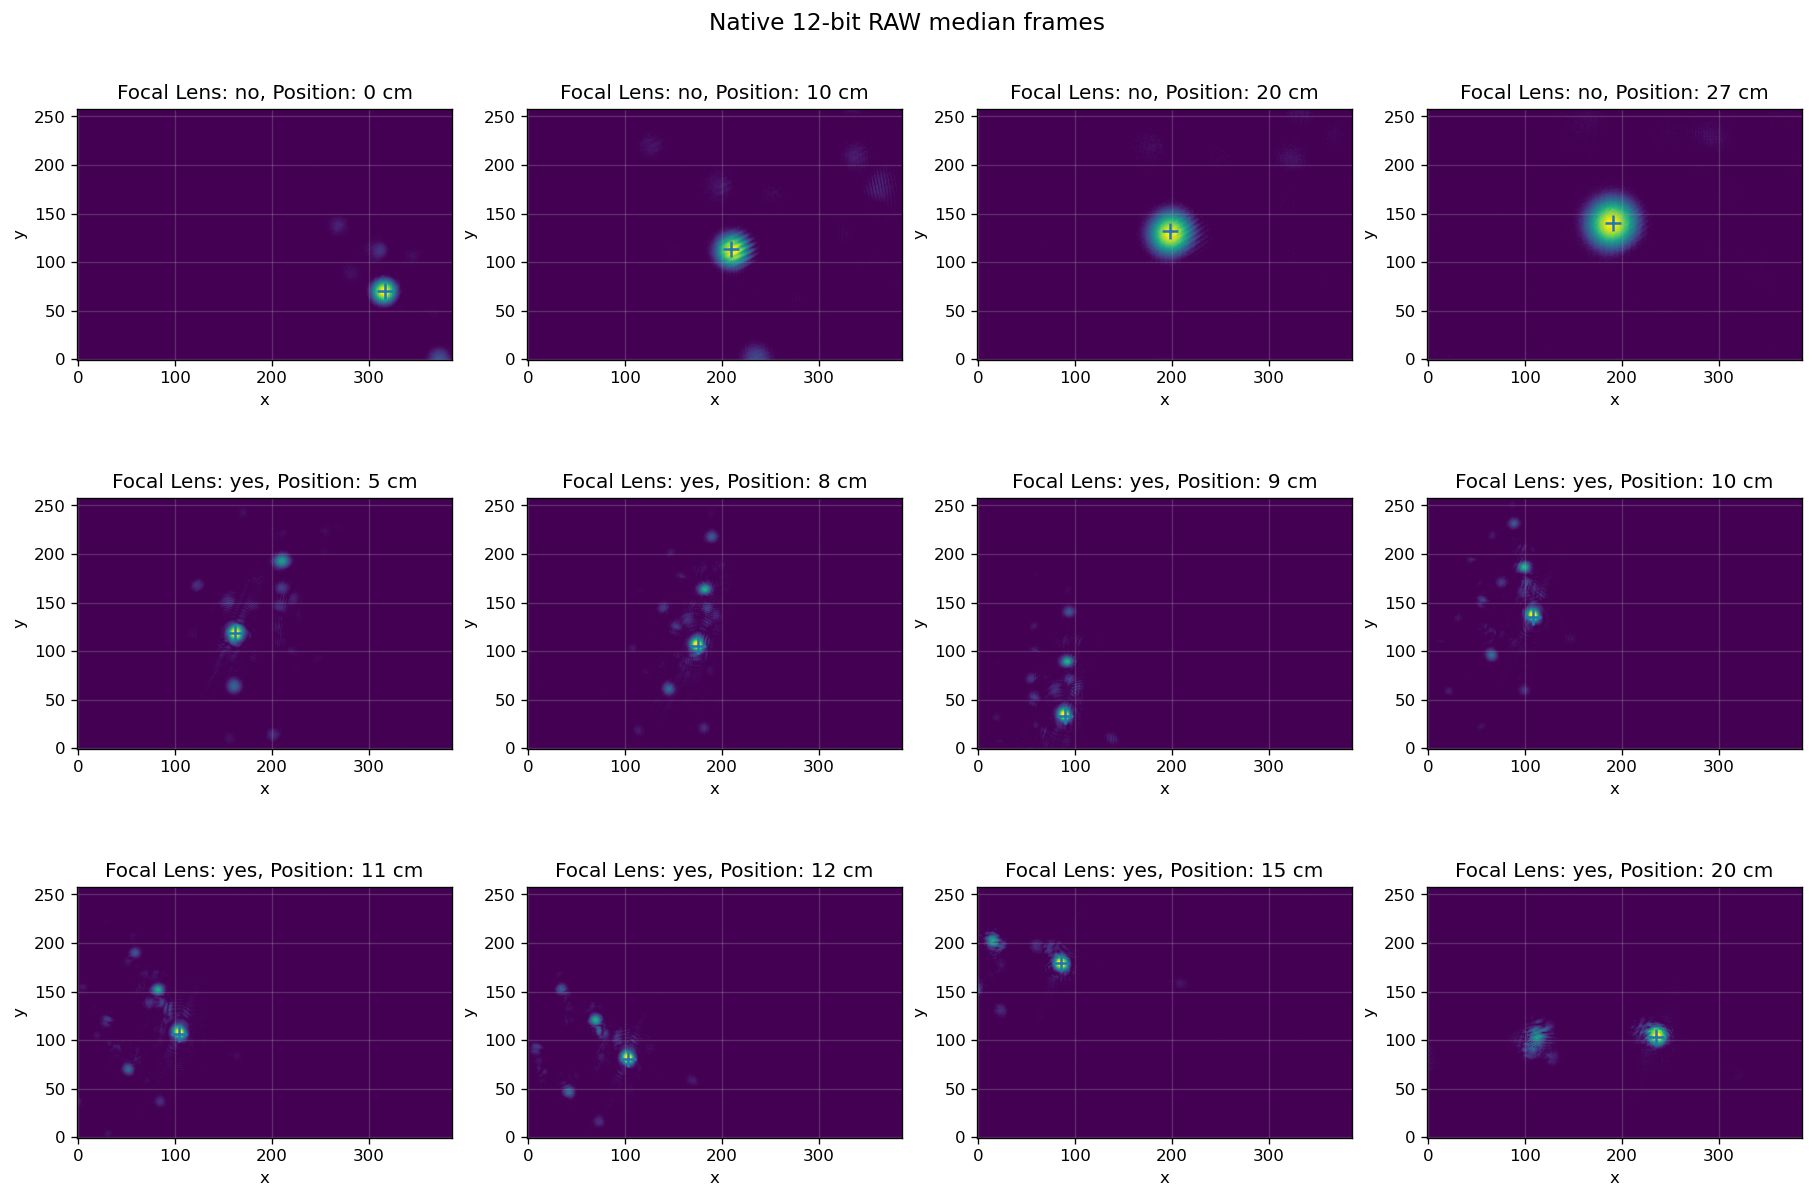

In [4]:
if DATA_ROOT is not None:
    raw_dir = DATA_ROOT / "532nm_Spatial" / "Beam"
    camera = CameraConfig(sensor_pixel_pitch_um=2.4, magnification=1.0, wavelength_nm=532.0)
    index = pd.DataFrame(parse_spatial_filename(p) for p in sorted(raw_dir.glob("*.raw")))
    grouped_files = list(index.groupby(["focal", "position_cm"], sort=True))
    fig, axes = plt.subplots(3, 4, figsize=(15, 10), constrained_layout=True)
    for ax, ((focal, z_cm), table) in zip(axes.ravel(), grouped_files):
        imgs = [green_superpixel(load_bayer_raw(raw_dir / name, camera)) for name in table["file"]]
        median = np.median(np.stack(imgs), axis=0)
        plane, _, _ = estimate_background_plane(median, border_px=camera.border_px_green)
        corrected = np.clip(median - plane, 0, None)
        view = corrected[::4, ::4]
        vmax = np.percentile(view, 99.98)
        y, x = np.unravel_index(np.argmax(corrected), corrected.shape)
        ax.imshow(view, origin="lower", vmin=0, vmax=max(vmax, 1))
        ax.plot(x / 4, y / 4, "+", ms=10, mew=1.5)
        ax.set_title(f"Focal Lens: {focal}, Position: {z_cm:g} cm")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    for ax in axes.ravel()[len(grouped_files):]:
        ax.axis("off")
    fig.suptitle("Native 12-bit RAW median frames", fontsize=14)
    fig.savefig(FIGURE_DIR / "spatial_native_contact_sheet_v2.png", bbox_inches="tight")
    plt.show()
else:
    print("Raw data not mounted; see the executed notebook or figures directory.")

## Beam size, ellipticity, and background/reflection sensitivity

Error bars are one standard deviation across the three independent frames at each position. They quantify repeatability only. Solid markers are unsaturated in the selected primary aperture; open markers are saturation-affected.

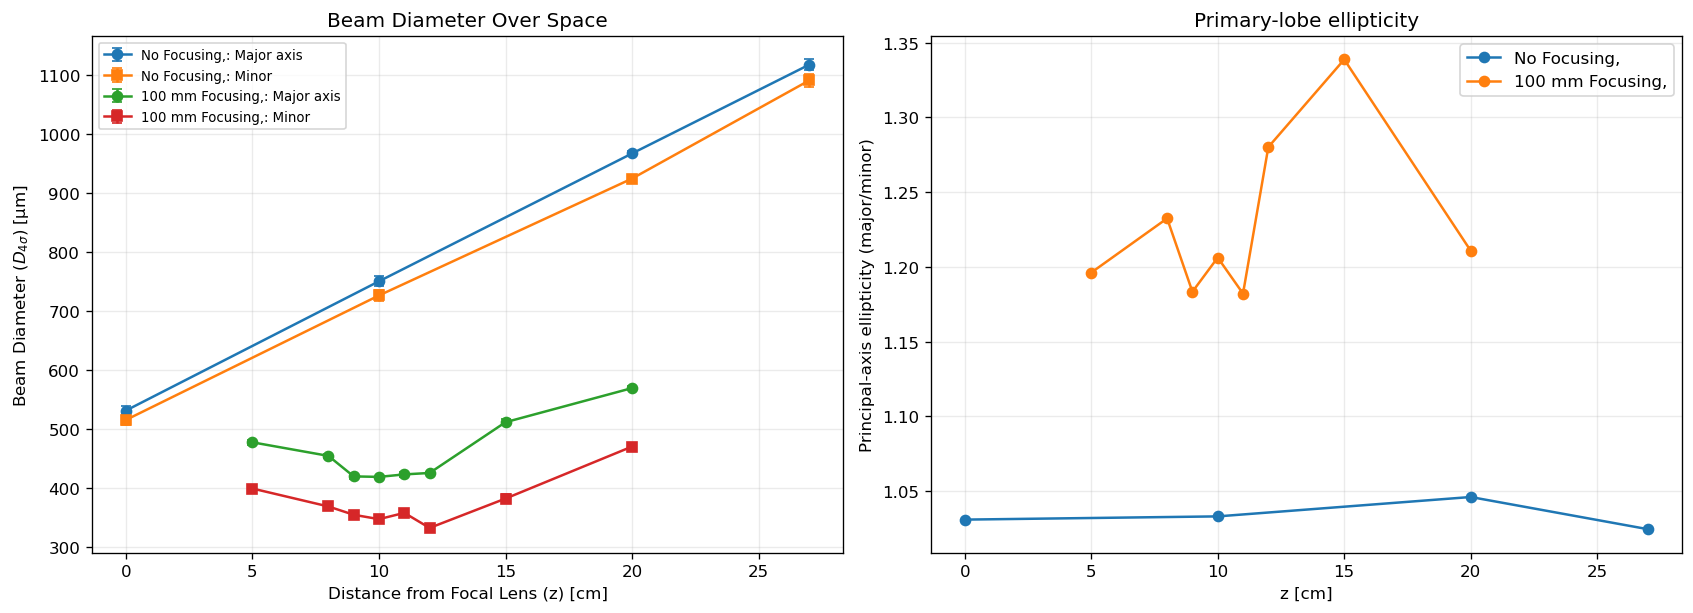

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for focal, label in [("no", "No Focusing,"), ("yes", "100 mm Focusing,")]:
    d = groups[groups.focal.eq(focal)].sort_values("position_cm")
    for measurement, marker in [("d4sigma_major_um", "o"), ("d4sigma_minor_um", "s")]:
        name = "Major axis" if "major" in measurement else "Minor"
        axes[0].errorbar(
            d.position_cm, d[f"{measurement}_mean"], yerr=d[f"{measurement}_std"],
            marker=marker, capsize=3, label=f"{label}: {name}"
        )
    axes[1].plot(d.position_cm, d.primary_ellipticity_mean, marker="o", label=label)
axes[0].set_xlabel("Distance from Focal Lens (z) [cm]")
axes[0].set_ylabel(r"Beam Diameter ($D_{4\sigma}$) [µm]")
axes[0].set_title("Beam Diameter Over Space")
axes[0].legend(fontsize=8)
axes[1].set_xlabel("z [cm]")
axes[1].set_ylabel("Principal-axis ellipticity (major/minor)")
axes[1].set_title("Primary-lobe ellipticity")
axes[1].legend()
fig.savefig(FIGURE_DIR / "spatial_size_ellipticity_v2.png", bbox_inches="tight")
plt.show()

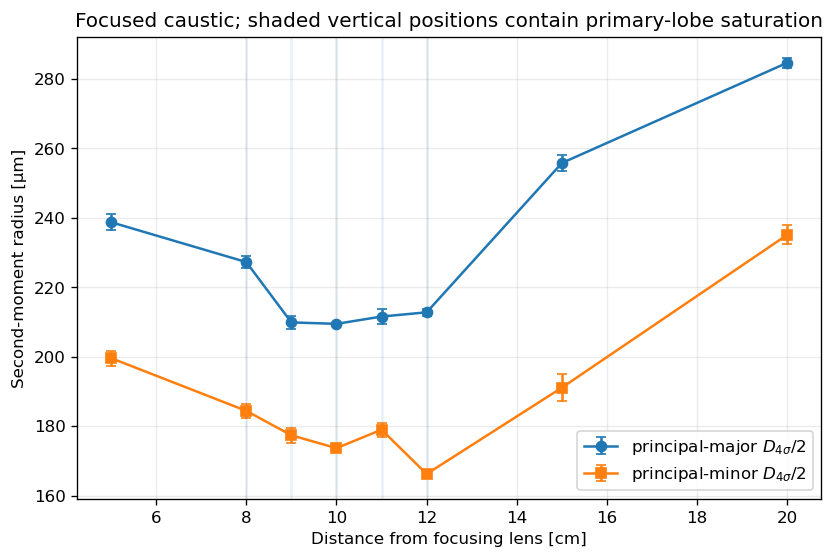

In [6]:
focused = groups[groups.focal.eq("yes")].sort_values("position_cm")
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    focused.position_cm, focused.d4sigma_major_um_mean / 2,
    yerr=focused.d4sigma_major_um_std / 2, marker="o", capsize=3,
    label=r"principal-major $D_{4\sigma}/2$"
)
ax.errorbar(
    focused.position_cm, focused.d4sigma_minor_um_mean / 2,
    yerr=focused.d4sigma_minor_um_std / 2, marker="s", capsize=3,
    label=r"principal-minor $D_{4\sigma}/2$"
)
for _, row in focused[focused.primary_saturation_any].iterrows():
    ax.axvline(row.position_cm, alpha=0.10)
ax.set_xlabel("Distance from focusing lens [cm]")
ax.set_ylabel("Second-moment radius [µm]")
ax.set_title("Focused caustic; shaded vertical positions contain primary-lobe saturation")
ax.legend()
fig.savefig(FIGURE_DIR / "spatial_focused_caustic_v2.png", bbox_inches="tight")
plt.show()

## Provisional caustic fits and method sensitivity

All eight focused positions can be fit numerically, but that does not make the result reportable as a standards-grade \(M^2\). The analysis deliberately compares sensor-axis moments, principal-axis moments, and model-dependent Gaussian radii. A large method spread is evidence that model and aperture choices matter.

The conservative coverage diagnostic asks for at least ten positions, at least three points on each side, at least four points within one fitted Rayleigh range, and approximately two Rayleigh ranges of extent on each side. This is a project quality-control heuristic, not a declaration of ISO compliance.

In [7]:
show = fits[fits.fit_weighting.eq("repeatability_sd")][[
    "display_name", "w0_um", "z0_cm", "m2", "m2_std",
    "rayleigh_range_cm", "far_field_divergence_mrad", "r2",
    "left_span_in_rayleigh_ranges", "right_span_in_rayleigh_ranges",
    "coverage_heuristic_pass", "reported_status",
]].copy()
display(show.round(4))

principal = show[show.display_name.str.contains("principal")]
print(
    "Provisional principal-axis M² range: "
    f"{principal.m2.min():.3f} to {principal.m2.max():.3f}. "
    "This range is a sensitivity result, not a final M² measurement."
)

,display_name,w0_um,z0_cm,m2,m2_std,rayleigh_range_cm,far_field_divergence_mrad,r2,left_span_in_rayleigh_ranges,right_span_in_rayleigh_ranges,coverage_heuristic_pass,reported_status
1,D4sigma x radius,173.1597,10.3476,2.3134,0.0253,7.6539,2.2624,0.9734,0.6987,1.2611,False,provisional sensitivity analysis; not a standards-grade M2 result
3,D4sigma y radius,208.7286,11.1308,1.9645,0.0590,13.0963,1.5938,0.3882,0.4681,0.6772,False,provisional sensitivity analysis; not a standards-grade M2 result
5,D4sigma principal-major radius,209.3863,10.3428,2.5387,0.0388,10.1983,2.0531,0.8390,0.5239,0.9469,False,provisional sensitivity analysis; not a standards-grade M2 result
7,D4sigma principal-minor radius,171.8708,11.2820,1.8143,0.0377,9.6147,1.7876,0.9433,0.6534,0.9067,False,provisional sensitivity analysis; not a standards-grade M2 result
9,Gaussian 1/e2 major radius,180.6378,10.6819,2.1503,0.0116,8.9609,2.0158,0.9762,0.6341,1.0399,False,provisional sensitivity analysis; not a standards-grade M2 result
11,Gaussian 1/e2 minor radius,159.9071,11.2611,1.8702,0.0070,8.0740,1.9805,0.9822,0.7755,1.0824,False,provisional sensitivity analysis; not a standards-grade M2 result


Provisional principal-axis M² range: 1.814 to 2.539. This range is a sensitivity result, not a final M² measurement.


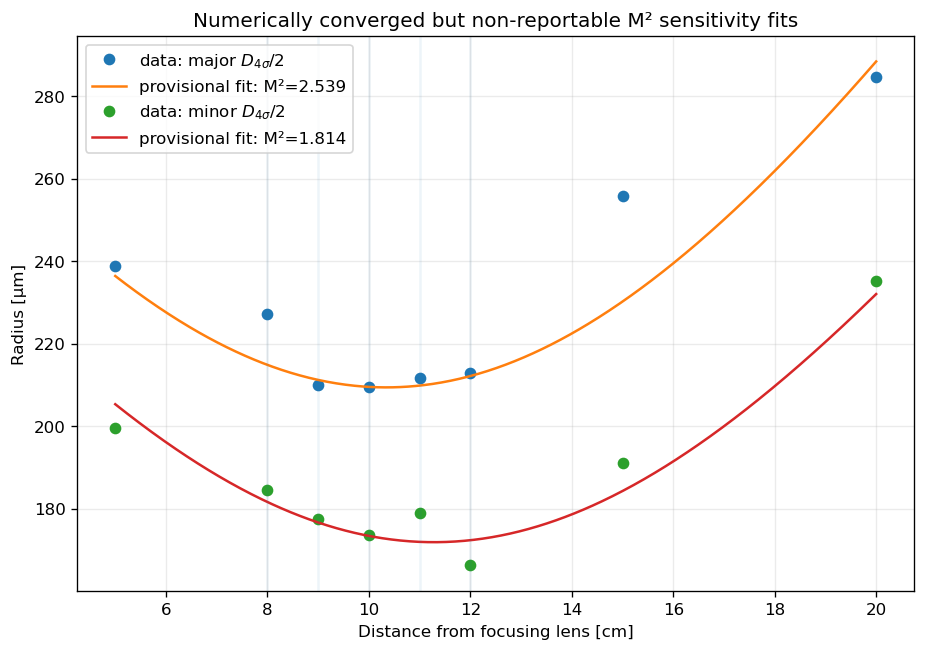

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
z_dense = np.linspace(focused.position_m.min(), focused.position_m.max(), 500)
for measurement, label in [
    ("d4sigma_major_um", r"major $D_{4\sigma}/2$"),
    ("d4sigma_minor_um", r"minor $D_{4\sigma}/2$"),
]:
    fit = fits[(fits.measurement.eq(measurement)) & fits.fit_weighting.eq("repeatability_sd")].iloc[0]
    radius = focused[f"{measurement}_mean"] / 2
    ax.plot(focused.position_cm, radius, "o", label=f"data: {label}")
    curve = beam_radius_model(z_dense, fit.w0_um * 1e-6, fit.z0_cm / 100, fit.m2, 532e-9) * 1e6
    ax.plot(z_dense * 100, curve, label=f"provisional fit: M²={fit.m2:.3f}")
for z in focused.loc[focused.primary_saturation_any, "position_cm"]:
    ax.axvline(z, alpha=0.08)
ax.set_xlabel("Distance from focusing lens [cm]")
ax.set_ylabel("Radius [µm]")
ax.set_title("Numerically converged but non-reportable M² sensitivity fits")
ax.legend()
fig.savefig(FIGURE_DIR / "spatial_provisional_m2_v2.png", bbox_inches="tight")
plt.show()

### Why the result remains non-reportable

- There are eight focused z positions, not a dense caustic.
- Only three focused positions are strictly unsaturated in the selected primary aperture.
- The waist-region points are precisely the points most affected by saturation.
- The measured left/right extents are less than roughly 1.3 fitted Rayleigh ranges for the displayed principal/sensor-axis fits, not a robust far-field sampling on both sides.
- The global sensor-y fit has poor \(R^2\), while principal-axis and Gaussian fits differ materially.
- z-position uncertainty, exact lens orientation, camera black-level/gamma, and a matched native dark frame are absent.

The correct graduate-level statement is: **the dataset shows a focused caustic and supports a provisional \(M^2\) sensitivity range, but not a standards-grade reported \(M^2\).**

## Unfocused beam expansion

The no-lens series is monotonic over 0–27 cm. A linear radius slope can be reported over that measured interval, but it is not automatically a far-field divergence because the location of the source waist is not measured.

In [9]:
display(no_lens_expansion[[
    "display_name", "apparent_radius_slope_mrad", "linear_r2", "interpretation"
]].round(4))

,display_name,apparent_radius_slope_mrad,linear_r2,interpretation
0,D4sigma x radius,1.0638,0.9998,local expansion slope over measured range; not a far-field divergence or M2
1,D4sigma y radius,1.0763,0.9981,local expansion slope over measured range; not a far-field divergence or M2
2,D4sigma principal-major radius,1.0853,1.0000,local expansion slope over measured range; not a far-field divergence or M2
3,D4sigma principal-minor radius,1.0546,0.9990,local expansion slope over measured range; not a far-field divergence or M2
4,Gaussian 1/e2 major radius,1.2641,0.9982,local expansion slope over measured range; not a far-field divergence or M2
5,Gaussian 1/e2 minor radius,1.2316,0.9970,local expansion slope over measured range; not a far-field divergence or M2


## Centroid trajectory versus pointing stability

The frame-to-frame centroid repeatability at one z position is typically micrometre-scale, while the centroid changes by millimetres between separately acquired z positions. These images are not a time series, so the result is a **centroid trajectory**, not pointing jitter. The focused trajectory is not well described by one straight beam axis.

,focal,subset,n_positions,within_position_x_sd_median_um,within_position_y_sd_median_um,between_position_x_peak_to_peak_mm,between_position_y_peak_to_peak_mm,interpretation,apparent_x_axis_slope_mrad,apparent_x_axis_linear_r2,apparent_y_axis_slope_mrad,apparent_y_axis_linear_r2
0,no,all_positions,4,2.3884,0.1888,2.4162,1.3449,centroid trajectory across separate z acquisitions; not time-domain pointing jitter,-8.4336,0.7824,4.8695,0.9374
1,no,z_ge_10_cm_diagnostic,3,1.9616,0.1706,0.4051,0.5347,centroid trajectory across separate z acquisitions; not time-domain pointing jitter,-2.3772,0.9995,3.1599,0.9979
2,yes,all_positions,8,3.4660,0.6156,2.8871,2.7690,centroid trajectory across separate z acquisitions; not time-domain pointing jitter,6.7898,0.0935,3.7283,0.0462


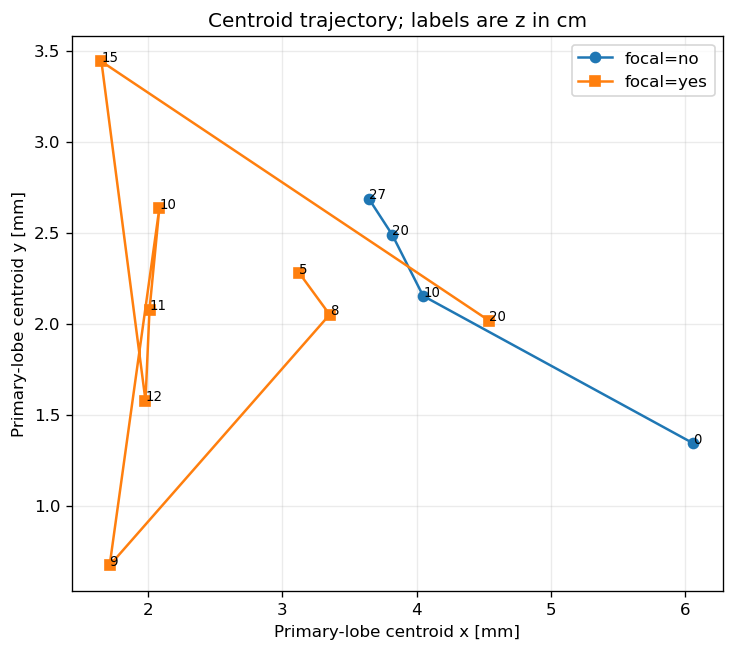

In [10]:
display(pointing.round(4))

fig, ax = plt.subplots(figsize=(7, 6))
for focal, marker in [("no", "o"), ("yes", "s")]:
    d = groups[groups.focal.eq(focal)].sort_values("position_cm")
    ax.plot(d.primary_center_x_mm_mean, d.primary_center_y_mm_mean, marker=marker, label=f"focal={focal}")
    for _, row in d.iterrows():
        ax.annotate(f'{row.position_cm:g}', (row.primary_center_x_mm_mean, row.primary_center_y_mm_mean), fontsize=8)
ax.set_xlabel("Primary-lobe centroid x [mm]")
ax.set_ylabel("Primary-lobe centroid y [mm]")
ax.set_title("Centroid trajectory; labels are z in cm")
ax.legend()
fig.savefig(FIGURE_DIR / "spatial_centroid_trajectory_v2.png", bbox_inches="tight")
plt.show()

## Supplemental legacy PNG scans

The earlier scans contain more z positions and background-reference PNGs, but they are 8-bit RGB/demosaiced files rather than native BayerRG12. Nearly all focused PNG frames have thousands of saturated pixels in the selected lobe. They are useful for qualitative beam-evolution checks, but they are not combined with the RAW series and do not rescue the \(M^2\) claim.

,focal,frames,frames_with_primary_saturation,z_min_mm,z_max_mm
0,no,12,10,0.0,250.0
1,yes,8,8,70.0,250.0


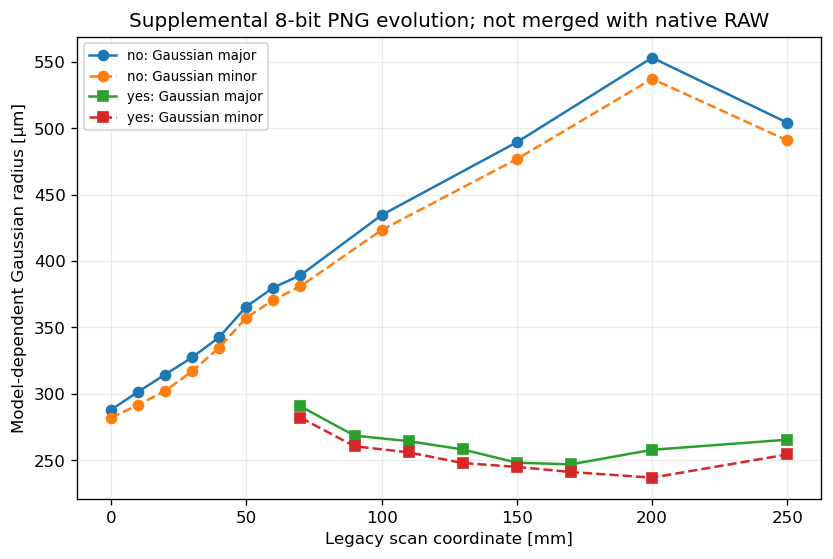

In [11]:
legacy_summary = legacy.groupby("focal").agg(
    frames=("file", "count"),
    frames_with_primary_saturation=("primary_saturation_present", "sum"),
    z_min_mm=("position_mm", "min"),
    z_max_mm=("position_mm", "max"),
).reset_index()
display(legacy_summary)

fig, ax = plt.subplots(figsize=(8, 5))
for focal, marker in [("no", "o"), ("yes", "s")]:
    d = legacy[legacy.focal.eq(focal)].sort_values("position_mm")
    ax.plot(d.position_mm, d.gaussian_w_major_um, marker=marker, label=f"{focal}: Gaussian major")
    ax.plot(d.position_mm, d.gaussian_w_minor_um, marker=marker, linestyle="--", label=f"{focal}: Gaussian minor")
ax.set_xlabel("Legacy scan coordinate [mm]")
ax.set_ylabel("Model-dependent Gaussian radius [µm]")
ax.set_title("Supplemental 8-bit PNG evolution; not merged with native RAW")
ax.legend(fontsize=8)
fig.savefig(FIGURE_DIR / "spatial_legacy_png_v2.png", bbox_inches="tight")
plt.show()

## Spatial confidence verdict

| Quantity | Verdict | Interpretation |
|---|---|---|
| Selected primary-lobe size versus z | **Supported with caveat** | Direct pixel scale is known; no relay magnification. Saturation and absent native dark frames limit waist accuracy. |
| Ellipticity and orientation | **Supported with caveat** | Valid for the selected primary aperture; rings and ghosts make full-field quality worse. |
| Within-position repeatability | **Supported** | Three independent frames per RAW position; not a total uncertainty. |
| Time-domain pointing jitter | **Not supported** | Frames were taken at different z positions, not as a continuous time sequence. |
| Unfocused local expansion slope | **Supported with caveat** | Local slope over 0–27 cm, not a guaranteed far-field divergence. |
| Focused \(M^2\) | **Provisional only** | Numerical range about 1.81–2.54 depending on axis/method; saturation and caustic coverage prevent a final claim. |